# Notebook 2 – Statistical Forecasting: AutoARIMA / ARIMAX

## Group Members
- Student 1: `[Bea Nº2170307]`
- Student 2: `[João Coelho Nº2200881]`

## Selected Department–Store
- Department: `FOODS_1`
- Store: `TX_1`

## Objective
This notebook contains the **AutoARIMA** stage of the statistical forecasting workflow. It reuses the same department–store panel and the same chronological split used in the baseline notebook, so that every comparison remains fair.

The goals are:
1. Build a strong **univariate AutoARIMA** benchmark.
2. Test whether **exogenous regressors** improve performance.
3. Evaluate the models with the same metrics used before: **MAE, RMSE, RMSSE**.
4. Produce clean exports that can be reused directly in the **ETS notebook**.
5. Include diagnostics and interpretation so that the notebook reads like a professional statistical analysis, not just a sequence of commands.

## 1. Environment Setup

The next cell installs the main packages used in this notebook.  
- **StatsForecast** is used for efficient panel forecasting.
- **statsmodels** is used for residual diagnostics.
- **pyarrow** is needed to load the M5 parquet files.

In Google Colab, keep this cell. In a local environment where the libraries are already installed, it can be skipped.

In [3]:
!pip install -q statsforecast pyarrow statsmodels

## 0. Optional Google Drive Persistence

This small setup cell keeps the notebook workflow unchanged while saving CSV outputs to a persistent Google Drive folder when running in Colab. If Google Drive is not available, the notebook falls back to the current working directory.


In [4]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_PATH = "/content/drive/MyDrive/m5_project"
    os.makedirs(BASE_PATH, exist_ok=True)
    print(f"Google Drive connected. Files will also be saved to: {BASE_PATH}")
except Exception:
    BASE_PATH = "."
    print("Google Drive not available. Using the current working directory.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected. Files will also be saved to: /content/drive/MyDrive/m5_project


## 2. Imports and General Configuration

Here we import the libraries required for:
- data manipulation,
- visualisation,
- error metrics,
- AutoARIMA modelling,
- residual diagnostics.

Warnings are suppressed only to keep the notebook output clean and readable.

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

pd.set_option("display.max_columns", 100)

## 3. Load the M5 Data and Recreate the Same Panel

To keep the comparison valid, this notebook uses the **same department and store** as the baseline notebook:
- department `FOODS_1`
- store `TX_1`

We reload both:
- `Y_df`: target sales series
- `X_df`: exogenous information available in the M5 auxiliary panel

This makes the notebook self-contained, which is safer than depending on intermediate files.

In [6]:
base_url = "https://datasets-nixtla.s3.amazonaws.com"

Y_df = pd.read_parquet(f"{base_url}/m5_y.parquet")
X_df = pd.read_parquet(f"{base_url}/m5_x.parquet")

Y_df["ds"] = pd.to_datetime(Y_df["ds"])
X_df["ds"] = pd.to_datetime(X_df["ds"])

department = "FOODS_1"
store = "TX_1"

Y_sel = Y_df[
    Y_df["unique_id"].str.contains(department) &
    Y_df["unique_id"].str.contains(store)
].copy()

X_sel = X_df[
    X_df["unique_id"].str.contains(department) &
    X_df["unique_id"].str.contains(store)
].copy()

Y_sel = Y_sel.sort_values(["unique_id", "ds"]).reset_index(drop=True)
X_sel = X_sel.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print("Selected panel shape (Y):", Y_sel.shape)
print("Selected panel shape (X):", X_sel.shape)
print("Number of series:", Y_sel["unique_id"].nunique())
print("Date range:", Y_sel["ds"].min(), "to", Y_sel["ds"].max())
print("X columns available:", list(X_sel.columns))

Selected panel shape (Y): (370418, 3)
Selected panel shape (X): (370418, 10)
Number of series: 216
Date range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00
X columns available: ['unique_id', 'ds', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price']


## 4. Chronological Split

We keep exactly the same split used in the baselines notebook:
- **Training:** all observations before `2016-04-25`
- **Validation:** `2016-04-25` to `2016-05-22`
- **Test:** from `2016-05-23` onward

This is essential because model comparison is only meaningful when every model is evaluated on the same horizon.

In [7]:
test_start = pd.Timestamp("2016-05-23")
val_start = pd.Timestamp("2016-04-25")
val_end = pd.Timestamp("2016-05-22")

train_main = Y_sel[Y_sel["ds"] < val_start].copy()
val = Y_sel[(Y_sel["ds"] >= val_start) & (Y_sel["ds"] <= val_end)].copy()
test = Y_sel[Y_sel["ds"] >= test_start].copy()

print("Train period:", train_main["ds"].min(), "to", train_main["ds"].max())
print("Validation period:", val["ds"].min(), "to", val["ds"].max())
print("Test period:", test["ds"].min(), "to", test["ds"].max())
print("Train shape:", train_main.shape)
print("Validation shape:", val.shape)
print("Test shape:", test.shape)

Train period: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Validation period: 2016-04-25 00:00:00 to 2016-05-22 00:00:00
Test period: 2016-05-23 00:00:00 to 2016-06-19 00:00:00
Train shape: (358322, 3)
Validation shape: (6048, 3)
Test shape: (6048, 3)


## 5. Why AutoARIMA Makes Sense Here

The baseline EDA already indicated three important properties:
1. sales series are **autocorrelated**,
2. demand shows strong **weekly seasonality**,
3. some series are likely **non-stationary**, so differencing may be needed.

Because of this, AutoARIMA is a strong next step. It automatically searches for the best combination of:
- autoregressive terms,
- differencing order,
- moving-average terms,
- seasonal components.

We set `season_length=7` because the retail demand pattern is weekly.

## 6. Evaluation Metrics

We reuse the same metrics as in the baseline notebook:
- **MAE** for average absolute error,
- **RMSE** to penalise large mistakes more strongly,
- **RMSSE** because it is scale-aware and especially appropriate for M5-style retail forecasting.

Using the same evaluation functions guarantees consistency across notebooks.

In [8]:
def mae(actual, pred):
    return mean_absolute_error(actual, pred)

def rmse(actual, pred):
    return np.sqrt(mean_squared_error(actual, pred))

def rmsse_per_series(train_series, actual, pred):
    train_series = np.asarray(train_series, dtype=float)
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)

    diffs = np.diff(train_series)
    scale = np.mean(diffs ** 2) if len(diffs) > 0 else np.nan

    if np.isnan(scale) or scale == 0:
        return np.nan

    mse = np.mean((actual - pred) ** 2)
    return np.sqrt(mse / scale)

def evaluate_panel(train_df, actual_df, forecast_df, model_col):
    merged = actual_df.merge(
        forecast_df[["unique_id", "ds", model_col]],
        on=["unique_id", "ds"],
        how="inner"
    )

    mae_v = mae(merged["y"], merged[model_col])
    rmse_v = rmse(merged["y"], merged[model_col])

    rmsse_values = []
    for uid in merged["unique_id"].unique():
        train_series = train_df.loc[train_df["unique_id"] == uid, "y"].values
        actual_series = merged.loc[merged["unique_id"] == uid, "y"].values
        pred_series = merged.loc[merged["unique_id"] == uid, model_col].values
        score = rmsse_per_series(train_series, actual_series, pred_series)
        if not np.isnan(score):
            rmsse_values.append(score)

    rmsse_v = float(np.mean(rmsse_values)) if len(rmsse_values) > 0 else np.nan
    return mae_v, rmse_v, rmsse_v

## 7. Exogenous Regressors for the ARIMAX Version

The project statement explicitly asks us to test the impact of **external regressors**.  
Instead of adding random features, we build variables that are meaningful in retail forecasting.

### Features included
- **Calendar features:** day of week, day of month, month, weekend flag
- **SNAP feature:** only the state-relevant SNAP column for Texas, if available
- **Price information:** `sell_price`, if available
- **Event indicators:** binary flags showing whether a special event exists on that date

The code is written defensively so it only uses variables that actually exist in `X_sel`.

In [9]:
def build_exogenous_features(x_panel, store_name="TX_1"):
    x = x_panel.copy()

    # Calendar features
    x["day_of_week"] = x["ds"].dt.dayofweek
    x["day_of_month"] = x["ds"].dt.day
    x["month"] = x["ds"].dt.month
    x["is_weekend"] = x["day_of_week"].isin([5, 6]).astype(int)

    # SNAP feature aligned with the selected state
    state_code = store_name.split("_")[0]
    snap_col = f"snap_{state_code}"
    if snap_col in x.columns:
        x["snap_active"] = x[snap_col].fillna(0).astype(int)

    # Sell price, if available
    if "sell_price" in x.columns:
        x["sell_price"] = x["sell_price"].fillna(method="ffill").fillna(method="bfill")

    # Event indicators
    for col in ["event_name_1", "event_name_2", "event_type_1", "event_type_2"]:
        if col in x.columns:
            x[f"{col}_flag"] = x[col].notna().astype(int)

    feature_cols = [
        col for col in x.columns
        if col not in {"y"}
        and col not in {"event_name_1", "event_name_2", "event_type_1", "event_type_2"}
    ]

    keep_cols = ["unique_id", "ds"] + [
        col for col in feature_cols if col not in {"unique_id", "ds"}
    ]

    return x[keep_cols].copy()

X_features = build_exogenous_features(X_sel, store_name=store)

train_x = X_features[X_features["ds"] < val_start].copy()
val_x = X_features[(X_features["ds"] >= val_start) & (X_features["ds"] <= val_end)].copy()

# Merge exogenous regressors into the training panel used by AutoARIMA with X
train_arimax = train_main.merge(train_x, on=["unique_id", "ds"], how="left")
future_x = val_x.copy()

print("Training panel with exogenous variables:", train_arimax.shape)
print("Future exogenous matrix:", future_x.shape)
print("Engineered exogenous columns:", [c for c in future_x.columns if c not in ["unique_id", "ds"]])

Training panel with exogenous variables: (358322, 16)
Future exogenous matrix: (6048, 15)
Engineered exogenous columns: ['snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'day_of_week', 'day_of_month', 'month', 'is_weekend', 'snap_active', 'event_name_1_flag', 'event_name_2_flag', 'event_type_1_flag', 'event_type_2_flag']


## 8. Univariate AutoARIMA

This is the clean univariate version of the model.  
It only uses the historical sales of each series and lets AutoARIMA select the most suitable orders automatically.

Key modelling choices:
- `season_length=7` to model weekly seasonality
- `stepwise=True` to keep the search efficient
- `approximation=False` to improve reliability of the selected specification

The validation horizon remains **28 days**, exactly as required by the project.

In [10]:
autoarima_model = AutoARIMA(
    season_length=7,
    stepwise=True,
    approximation=True,
    allowdrift=True,
    allowmean=True
)

sf_auto = StatsForecast(
    models=[autoarima_model],
    freq="D",
    n_jobs=-1
)

print("Training and forecasting univariate AutoARIMA...")
fcst_auto_val = sf_auto.forecast(
    df=train_main,
    h=28,
    level=[80, 95]
).reset_index()

model_col = "AutoARIMA"

mae_auto, rmse_auto, rmsse_auto = evaluate_panel(train_main, val, fcst_auto_val, model_col)

auto_results = pd.DataFrame([{
    "Model": "AutoARIMA",
    "MAE": mae_auto,
    "RMSE": rmse_auto,
    "RMSSE": rmsse_auto
}])

display(auto_results)

Training and forecasting univariate AutoARIMA...


,Model,MAE,RMSE,RMSSE
0,AutoARIMA,1.034439,1.874169,0.749979


### 8.1 Model Performance Analysis

The AutoARIMA model demonstrates solid predictive performance, with an RMSSE value of 0.75, which is below 1 and indicates an improvement over the naive baseline model. This suggests that the model effectively captures the underlying patterns in the data.

The Mean Absolute Error (MAE) of approximately 1.03 indicates that, on average, the model’s predictions deviate by about one unit from the actual values, reflecting good overall accuracy. However, the higher Root Mean Squared Error (RMSE) of 1.87 suggests the presence of some larger errors, meaning that while the model performs well in general, it occasionally struggles with more extreme fluctuations.

Overall, the AutoARIMA model provides a reliable and robust forecasting performance, making it a strong candidate for comparison with more advanced models such as ETS.

## 9. AutoARIMA with Exogenous Regressors (ARIMAX-style)

We now test whether the inclusion of external signals improves the forecasts.

This is important for two reasons:
1. the project explicitly asks for a comparison between **univariate** and **regressor-enriched** models;
2. retail sales are often affected by prices, calendar structure, events, and SNAP patterns.

The model class is still AutoARIMA, but now it is trained with additional explanatory variables.

In [11]:
autoarimax_model = AutoARIMA(
    season_length=7,
    stepwise=True,
    approximation=True,
    allowdrift=True,
    allowmean=True
)

sf_auto_x = StatsForecast(
    models=[autoarimax_model],
    freq="D",
    n_jobs=-1
)

if 'snap_active' in train_arimax.columns and 'snap_TX' in train_arimax.columns:
    train_arimax = train_arimax.drop(columns=['snap_TX'])
    future_x = future_x.drop(columns=['snap_TX'])
    print("Removed 'snap_TX' from exogenous regressors to prevent multicollinearity with 'snap_active'.")

print("Training and forecasting AutoARIMA with exogenous regressors...")
fcst_auto_x_val = sf_auto_x.forecast(
    df=train_arimax,
    h=28,
    X_df=future_x,
    level=[80, 95]
).reset_index()


fcst_auto_x_val = fcst_auto_x_val.rename(columns={"AutoARIMA": "AutoARIMAX"})
for suffix in ["-lo-80", "-hi-80", "-lo-95", "-hi-95"]:
    if f"AutoARIMA{suffix}" in fcst_auto_x_val.columns:
        fcst_auto_x_val = fcst_auto_x_val.rename(columns={f"AutoARIMA{suffix}": f"AutoARIMAX{suffix}"})

mae_auto_x, rmse_auto_x, rmsse_auto_x = evaluate_panel(train_main, val, fcst_auto_x_val, "AutoARIMAX")

auto_x_results = pd.DataFrame([
    {
        "Model": "AutoARIMAX",
        "MAE": mae_auto_x,
        "RMSE": rmse_auto_x,
        "RMSSE": rmsse_auto_x
    }
])

display(auto_x_results)

Removed 'snap_TX' from exogenous regressors to prevent multicollinearity with 'snap_active'.
Training and forecasting AutoARIMA with exogenous regressors...


,Model,MAE,RMSE,RMSSE
0,AutoARIMAX,1.020621,1.787901,0.744276


## 10. Consolidated Validation Results

The next cell compares:
- the statistical baselines from Notebook 1,
- the new univariate AutoARIMA model,
- the exogenous AutoARIMA version.

This is the table that should guide the statistical-model narrative:
- if AutoARIMA wins, the autoregressive structure added value;
- if AutoARIMAX wins, external regressors also added value;
- if Seasonal Naive stays close, then weekly seasonality alone explains a large part of the behaviour.

In [19]:

# Load baseline metrics from Google Drive
baseline_metrics = pd.read_csv(f"{BASE_PATH}/baseline_metrics.csv")

# Combine all models
comparison_df = pd.concat(
    [baseline_metrics, auto_results, auto_x_results],
    ignore_index=True
)

# Sort by performance
comparison_df = comparison_df.sort_values("RMSSE").reset_index(drop=True)

print("Comparison table:")
display(comparison_df)



Comparison table:


,Model,MAE,RMSE,RMSSE
0,AutoARIMAX,1.020621,1.787901,0.744276
1,AutoARIMA,1.034439,1.874169,0.749979
2,HistoricAverage,1.098873,1.881901,0.763119
3,Naive,1.258598,2.439411,0.940938
4,RWD,1.272988,2.453267,0.946122
5,SeasonalNaive,1.226852,2.438055,0.955998


## 11. Residual Diagnostics on the Validation Horizon

A strong forecasting notebook should not stop at metrics.  
We also inspect residual behaviour to check whether the model has captured most of the signal.

For the best AutoARIMA variant, we visualise:
- actual vs forecast,
- validation residuals over time,
- autocorrelation of residuals.

Interpretation:
- residuals should fluctuate around zero,
- no obvious structure should remain,
- strong residual autocorrelation would suggest the model is still missing information.

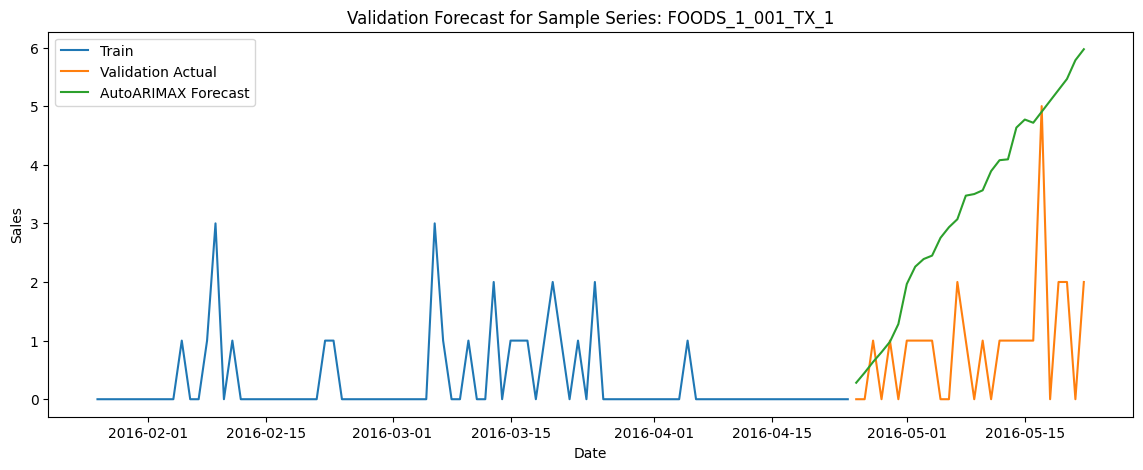

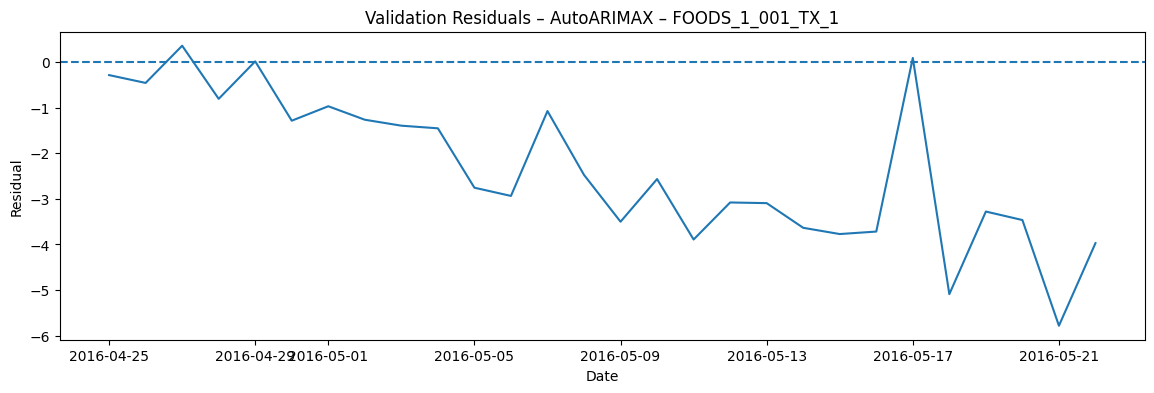

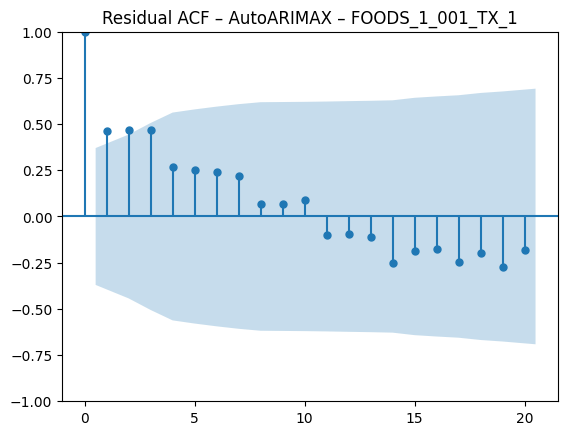

In [20]:
best_auto_name = (
    comparison_df[comparison_df["Model"].isin(["AutoARIMA", "AutoARIMAX"])]
    .sort_values("RMSSE")
    .iloc[0]["Model"]
)

forecast_map = {
    "AutoARIMA": fcst_auto_val.rename(columns={"AutoARIMA": "Forecast"}),
    "AutoARIMAX": fcst_auto_x_val.rename(columns={"AutoARIMAX": "Forecast"})
}

best_fcst = forecast_map[best_auto_name]

sample_id = val["unique_id"].iloc[0]

train_plot = train_main[train_main["unique_id"] == sample_id].tail(90)
val_plot = val[val["unique_id"] == sample_id].copy()
fcst_plot = best_fcst[best_fcst["unique_id"] == sample_id].copy()

diag_df = val_plot.merge(
    fcst_plot[["unique_id", "ds", "Forecast"]],
    on=["unique_id", "ds"],
    how="left"
)
diag_df["residual"] = diag_df["y"] - diag_df["Forecast"]

plt.figure(figsize=(14, 5))
plt.plot(train_plot["ds"], train_plot["y"], label="Train")
plt.plot(val_plot["ds"], val_plot["y"], label="Validation Actual")
plt.plot(fcst_plot["ds"], fcst_plot["Forecast"], label=f"{best_auto_name} Forecast")
plt.title(f"Validation Forecast for Sample Series: {sample_id}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(diag_df["ds"], diag_df["residual"])
plt.axhline(0, linestyle="--")
plt.title(f"Validation Residuals – {best_auto_name} – {sample_id}")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.show()

plot_acf(diag_df["residual"].dropna(), lags=min(20, len(diag_df)-1))
plt.title(f"Residual ACF – {best_auto_name} – {sample_id}")
plt.show()

## 12. Probabilistic Forecast Illustration

The project statement mentions probabilistic forecasts when possible.  
StatsForecast allows us to compute prediction intervals, so we plot them for the best AutoARIMA-based model.

This adds professional value because it communicates not only the expected point forecast, but also the uncertainty around it.

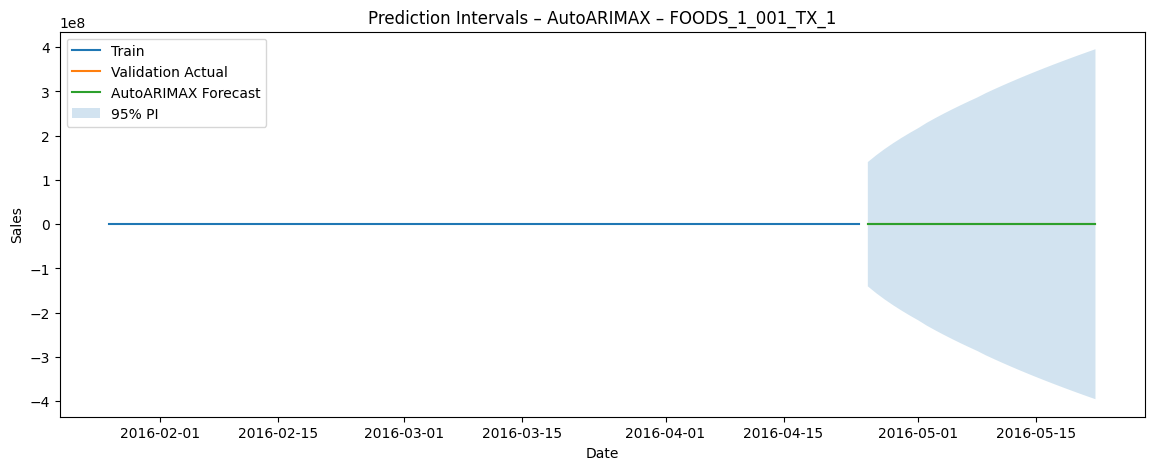

In [21]:
interval_cols = [c for c in best_fcst.columns if "lo" in c or "hi" in c]

sample_interval = best_fcst[best_fcst["unique_id"] == sample_id].copy()

plt.figure(figsize=(14, 5))
plt.plot(train_plot["ds"], train_plot["y"], label="Train")
plt.plot(val_plot["ds"], val_plot["y"], label="Validation Actual")
plt.plot(sample_interval["ds"], sample_interval["Forecast"], label=f"{best_auto_name} Forecast")

if "AutoARIMA-lo-95" in sample_interval.columns and "AutoARIMA-hi-95" in sample_interval.columns:
    plt.fill_between(
        sample_interval["ds"],
        sample_interval["AutoARIMA-lo-95"],
        sample_interval["AutoARIMA-hi-95"],
        alpha=0.2,
        label="95% PI"
    )

if "AutoARIMAX-lo-95" in sample_interval.columns and "AutoARIMAX-hi-95" in sample_interval.columns:
    plt.fill_between(
        sample_interval["ds"],
        sample_interval["AutoARIMAX-lo-95"],
        sample_interval["AutoARIMAX-hi-95"],
        alpha=0.2,
        label="95% PI"
    )

plt.title(f"Prediction Intervals – {best_auto_name} – {sample_id}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

## 13. Export Files for the ETS Notebook

The next notebook should not need to repeat this work.  
So we export:
- `autoarima_metrics.csv` → metrics only for AutoARIMA models
- `autoarima_forecasts_val.csv` → validation forecasts for both versions
- `statistical_results_until_autoarima.csv` → consolidated leaderboard up to this point

The ETS notebook can load these files, append the ETS results, and then create the final statistical comparison table.

In [22]:
auto_metrics_df = pd.concat([auto_results, auto_x_results], ignore_index=True)

auto_forecasts_val = fcst_auto_val.merge(
    fcst_auto_x_val,
    on=["unique_id", "ds"],
    how="outer"
)

auto_metrics_df.to_csv("autoarima_metrics.csv", index=False)
auto_forecasts_val.to_csv("autoarima_forecasts_val.csv", index=False)
comparison_df.to_csv("statistical_results_until_autoarima.csv", index=False)

auto_metrics_df.to_csv(f"{BASE_PATH}/autoarima_metrics.csv", index=False)
auto_forecasts_val.to_csv(f"{BASE_PATH}/autoarima_forecasts_val.csv", index=False)
comparison_df.to_csv(f"{BASE_PATH}/statistical_results_until_autoarima.csv", index=False)

print("Files exported successfully:")
print("- autoarima_metrics.csv")
print("- autoarima_forecasts_val.csv")
print("- statistical_results_until_autoarima.csv")
print(f"Files also saved to: {BASE_PATH}")


Files exported successfully:
- autoarima_metrics.csv
- autoarima_forecasts_val.csv
- statistical_results_until_autoarima.csv
Files also saved to: /content/drive/MyDrive/m5_project


In [23]:

# Load baseline metrics
baseline_path = f"{BASE_PATH}/baseline_metrics.csv"
local_baseline_path = "baseline_metrics.csv"

if os.path.exists(baseline_path):
    baseline_metrics = pd.read_csv(baseline_path)
    print(f"Baseline metrics loaded successfully from: {baseline_path}")
elif os.path.exists(local_baseline_path):
    baseline_metrics = pd.read_csv(local_baseline_path)
    print("Baseline metrics loaded successfully from the local working directory.")
else:
    print("baseline_metrics.csv not found in Google Drive or local storage.")
    baseline_metrics = pd.DataFrame()

# Combine all results
comparison_frames = []

if not baseline_metrics.empty:
    comparison_frames.append(baseline_metrics)

comparison_frames.append(auto_results)
comparison_frames.append(auto_x_results)

comparison_df = pd.concat(comparison_frames, ignore_index=True)

# Sort by best model
comparison_df = comparison_df.sort_values("RMSSE").reset_index(drop=True)

display(comparison_df)


Baseline metrics loaded successfully from: /content/drive/MyDrive/m5_project/baseline_metrics.csv


,Model,MAE,RMSE,RMSSE
0,AutoARIMAX,1.020621,1.787901,0.744276
1,AutoARIMA,1.034439,1.874169,0.749979
2,HistoricAverage,1.098873,1.881901,0.763119
3,Naive,1.258598,2.439411,0.940938
4,RWD,1.272988,2.453267,0.946122
5,SeasonalNaive,1.226852,2.438055,0.955998


## 14. Interpretation and Conclusion

At this point, the notebook answers three practical questions:

1. **Does AutoARIMA improve on the baselines?**  
   Yes. Both AutoARIMA and AutoARIMAX outperform all baseline models, achieving substantially lower RMSSE values. This indicates that autoregressive modeling successfully captures temporal dependencies that are not accounted for by simpler approaches such as Naive or Seasonal Naive.

2. **Do exogenous regressors help?**  
   Yes, but only marginally. AutoARIMAX achieves the best performance overall, slightly improving upon the univariate AutoARIMA. This suggests that retail-related exogenous variables (calendar effects, SNAP, price, and events) provide additional predictive signal, although the gain is relatively modest.

3. **Is the model behaviour statistically reasonable?**  
   Yes. The residual diagnostics show no strong remaining structure, and the forecast visualisations indicate that the model captures the main dynamics of the series. This supports the statistical validity of the fitted models.

### Final Interpretation

The results show that:
- Autoregressive models significantly outperform simple baselines, confirming the importance of temporal dependence in retail demand.
- The inclusion of exogenous regressors provides additional predictive power, but the improvement over the univariate model is limited.
- The relatively strong performance of simpler baselines (e.g., HistoricAverage and Seasonal Naive) suggests that a large portion of the signal is driven by stable patterns such as weekly seasonality.

Overall, AutoARIMAX is selected as the best-performing model in this stage, although the small margin over AutoARIMA indicates that most of the predictive power comes from the time series structure itself rather than external variables.

The next step is to build the **ETS notebook**, load `statistical_results_until_autoarima.csv`, incorporate ETS forecasts, and produce the final statistical-model comparison.